# Naive Q&A vs controlled, mode-targeted Q&A

This notebook extends [`1_RAG_naive.ipynb`](./1_RAG_naive.ipynb) with a matched comparison:

- **Naive Q&A (control):** one model, one chunk, and one plain prompt generate each question and answer.
- **Controlled Q&A:** one model uses mode-specific instructions and answer contracts for plain factual, format, vocabulary, multi-constraint, multi-chunk, out-of-scope, and not-specified questions.

The experiment writes JSONL records and reports mode-level metrics. It evaluates a stratified, evenly spaced sample from every available document rather than selecting random chunks from one document. Set `RUN_GENERATION = True` to call the configured model; the default is `False` so the analysis can be rerun from saved records without incurring API costs.

## 1. Setup

The setup, model client, document paths, and output layout follow `1_RAG_naive.ipynb`.

In [21]:
import json
import logging
import os
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aieng.syn_data.text import (
    LLMSettings,
    OpenAICompatibleClient,
    load_implementation_dotenv,
    use_repo_root,
)
from aieng.syn_data.text.documents import paragraphs_from_document
from aieng.syn_data.text.schemas import DocumentRole, DocumentSpec
from rich.console import Console

repo_root = use_repo_root()
load_implementation_dotenv()
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
console = Console(width=110)


In [22]:
SEED = 42
random.seed(SEED)

SOURCE_DOCS_DIR = repo_root / "implementations/qa_text_generation/data/documents"
DATA_DIR = repo_root / "implementations/qa_text_generation/output/data"
OUT_DIR = repo_root / "implementations/qa_text_generation/output/qa_experiments"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

CHUNKS_PATH = DATA_DIR / "chunks.jsonl"
NAIVE_PATH = OUT_DIR / "naive_mode_comparison.jsonl"
CONTROLLED_PATH = OUT_DIR / "controlled_mode_comparison.jsonl"
LEGACY_NAIVE_PATH = OUT_DIR / "naive_raw.jsonl"
LEGACY_CONTROLLED_PATH = OUT_DIR / "controlled_raw.jsonl"
MODEL = os.getenv("TEACHER_MODEL", "gpt-4o")
SAMPLES_PER_DOCUMENT = 8
SAMPLING_STRATEGY = "stratified_evenly_spaced"
RUN_GENERATION = False


## 2. Load the same document chunks

The control condition is deliberately single-chunk. Controlled multi-chunk questions use the next selected chunk from the same document, while all other controlled modes use only the primary chunk. Existing chunks from `1_RAG_naive.ipynb` are reused when available; all available documents are included and an evenly spaced sample is taken from each one. This gives document coverage and reduces the chance that results depend on one lucky random sample.

In [23]:
def load_chunks():
    if CHUNKS_PATH.is_file():
        records = [json.loads(line) for line in CHUNKS_PATH.read_text(encoding="utf-8").splitlines() if line.strip()]
        return pd.DataFrame(records).reset_index(drop=True)

    document = SOURCE_DOCS_DIR / "cfpb_credit_card_agreement.txt"
    spec = DocumentSpec(
        doc_id="cfpb_credit_card_agreement",
        title="CFPB Credit Card Agreement",
        role=DocumentRole.POLICY_DENSE,
        domain="finance",
        local_path=str(document),
    )
    text = document.read_text(encoding="utf-8")
    paragraphs = paragraphs_from_document(spec, text, min_chars=80)
    return pd.DataFrame([paragraph.to_dict() for paragraph in paragraphs])

chunks = load_chunks()
text_column = next((name for name in ("text", "content", "text_content") if name in chunks), None)
if text_column is None:
    raise ValueError(f"No chunk text column found in {list(chunks.columns)}")
chunks = chunks.rename(columns={text_column: "text"}).copy()
chunks["text"] = chunks["text"].fillna("").astype(str)
chunks = chunks[chunks["text"].str.len() >= 80].reset_index(drop=True)
if chunks.empty:
    raise ValueError("The source document produced no usable chunks")
if "chunk_id" not in chunks:
    chunks["chunk_id"] = chunks.apply(
        lambda row: f"{row['doc_id']}::{row.get('para_id', row.name)}", axis=1
    )
chunks["chunk_id"] = chunks["chunk_id"].astype(str)
chunks["position"] = chunks.groupby("doc_id").cumcount()

def stratified_samples(frame, per_document):
    selected_frames = []
    for _, document in frame.groupby("doc_id", sort=True):
        count = min(per_document, len(document))
        positions = [round(value) for value in __import__("numpy").linspace(0, len(document) - 1, count)]
        selected_frames.append(document.iloc[positions])
    return pd.concat(selected_frames, ignore_index=True)

selected = stratified_samples(chunks, SAMPLES_PER_DOCUMENT)
console.print(
    f"Loaded {len(chunks)} chunks across {chunks['doc_id'].nunique()} documents; "
    f"selected {len(selected)} evenly spaced evaluation chunks"
)
display(selected.groupby("doc_id").size().rename("samples").to_frame())


Loaded 78 chunks across 4 documents; selected 31 evenly spaced evaluation chunks

,samples
doc_id,
cardholder_agreement,8
cfpb_credit_card_agreement,8
sec_investor_bulletin,8
visa_credit_card_agreement,7


## 3. Prompts and generation

The naive path makes a fresh question-answer record from one chunk with no mode instructions. The controlled path uses a mode-specific question contract and a structured answer contract. Both paths use the same configured model client and never provide context outside the supplied chunk(s).

In [24]:
CONTROLLED_MODES = (
    "plain_factual",
    "format",
    "vocabulary",
    "multi_constraint",
    "multi_chunk",
    "out_of_scope",
    "not_specified",
)

NAIVE_PROMPT = """Create exactly one question and answer from this document chunk.
Return JSON with exactly these fields: question, answer, evidence.
The evidence field must be a JSON array of short exact quotes from the chunk.
Do not use outside knowledge.

DOCUMENT CHUNK:
{context}"""

MODE_PROMPTS = {
    "plain_factual": "Ask one ordinary factual question answerable from chunk A.",
    "format": "Ask for two facts from chunk A and require the answer as a JSON object with exactly two named fields.",
    "vocabulary": "Ask for the meaning or use of a defined term explicitly present in chunk A.",
    "multi_constraint": "Ask one question requiring at least two separate facts or conditions from chunk A.",
    "multi_chunk": "Ask one question requiring a fact from chunk A and a fact from chunk B.",
    "out_of_scope": "Ask about an unrelated topic that cannot be answered from the document.",
    "not_specified": "Ask for an exact fact that is not stated in the supplied document chunks; do not invent a value.",
}

SPECIAL_QUESTIONS = {
    "out_of_scope": "What is the current weather in Toronto?",
    "not_specified": "What is the exact purchase APR stated in this agreement?",
}

CONTROLLED_QUESTION_PROMPT = """Create exactly one question for mode: {mode}.
Instruction: {instruction}
Return JSON with exactly one field: question. Do not answer it.
Use only the supplied chunks for document-grounded modes.

CHUNK A:
{context_a}

CHUNK B:
{context_b}"""

CONTROLLED_ANSWER_PROMPT = """Answer the question using only the supplied chunk(s).
Return JSON with exactly these fields: answer, evidence, abstained, format_valid.
Evidence must be an array of short exact quotes copied from the supplied chunk(s).
For out_of_scope, answer exactly OUT_OF_SCOPE and set abstained true.
For not_specified, answer exactly NOT_SPECIFIED and set abstained true.
For every other mode, answer every part and set abstained false.
For format, answer must be a valid JSON object with exactly the requested fields.
Never guess or use outside information.

MODE: {mode}
QUESTION: {question}

CHUNK A:
{context_a}

CHUNK B:
{context_b}"""

def parse_json_response(response):
    text = response.strip()
    if text.startswith("```"):
        text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text, flags=re.IGNORECASE | re.DOTALL)
    value = json.loads(text)
    if not isinstance(value, dict):
        raise ValueError("Model response was not a JSON object")
    return value

def complete_json(client, prompt, attempts=3):
    for attempt in range(attempts):
        try:
            return parse_json_response(client.complete(prompt, temperature=0.2, max_tokens=800))
        except (json.JSONDecodeError, TypeError, ValueError):
            if attempt == attempts - 1:
                raise
            time.sleep(2**attempt)

def evidence_list(value):
    if isinstance(value, list):
        return [str(item) for item in value if str(item).strip()]
    return [str(value)] if str(value).strip() else []

def controlled_format_valid(value):
    if isinstance(value, dict):
        return len(value) == 2
    try:
        parsed = json.loads(str(value))
    except (TypeError, json.JSONDecodeError):
        return False
    return isinstance(parsed, dict) and len(parsed) == 2

def make_record(method, mode, row, paired, question, answer, evidence, abstained=False, format_valid=None):
    return {
        "method": method,
        "mode": mode,
        "doc_id": str(row["doc_id"]),
        "chunk_id": str(row["chunk_id"]),
        "paired_chunk_id": str(paired["chunk_id"]) if mode == "multi_chunk" else "",
        "question": question,
        "answer": answer,
        "evidence": evidence_list(evidence),
        "abstained": bool(abstained),
        "format_valid": format_valid,
    }


In [25]:
def generate_records():
    client = OpenAICompatibleClient(LLMSettings.from_env(model_var="TEACHER_MODEL", default_model=MODEL))
    naive_records = []
    controlled_records = []

    for index, (_, row) in enumerate(selected.iterrows()):
        same_document = selected[selected["doc_id"] == row["doc_id"]]
        paired = same_document.iloc[(same_document.index.get_loc(index) + 1) % len(same_document)]
        naive = complete_json(client, NAIVE_PROMPT.format(context=row["text"]))
        naive_records.append(make_record(
            "naive", "plain_factual", row, row, naive.get("question", ""),
            naive.get("answer", ""), naive.get("evidence", []),
        ))

        for mode in CONTROLLED_MODES:
            context_b = paired["text"] if mode == "multi_chunk" else "(not used)"
            question = SPECIAL_QUESTIONS.get(mode)
            if question is None:
                question_result = complete_json(client, CONTROLLED_QUESTION_PROMPT.format(
                    mode=mode, instruction=MODE_PROMPTS[mode],
                    context_a=row["text"], context_b=context_b,
                ))
                question = str(question_result.get("question", "")).strip()
            answer_result = complete_json(client, CONTROLLED_ANSWER_PROMPT.format(
                mode=mode, question=question, context_a=row["text"], context_b=context_b,
            ))
            controlled_records.append(make_record(
                "controlled", mode, row, paired, question,
                answer_result.get("answer", ""), answer_result.get("evidence", []),
                answer_result.get("abstained", False),
                controlled_format_valid(answer_result.get("answer", "")) if mode == "format" else None,
            ))
    return naive_records, controlled_records

def write_jsonl(path, records):
    path.write_text("".join(json.dumps(record, ensure_ascii=False) + "\n" for record in records), encoding="utf-8")

if RUN_GENERATION:
    naive_records, controlled_records = generate_records()
    write_jsonl(NAIVE_PATH, naive_records)
    write_jsonl(CONTROLLED_PATH, controlled_records)
    console.print(f"Saved {len(naive_records)} naive records and {len(controlled_records)} controlled records")


## 4. Compare quality by mode

These are automated proxies, not a substitute for human review. Exact evidence checks quote containment; abstention and format checks test the explicit controlled contracts. Naive Q&A has one `plain_factual` row per selected chunk, while controlled Q&A has one row per requested mode per selected chunk. Interpret results by document and mode, not only as one pooled average.

In [26]:
def read_jsonl(path, fallback=None):
    source = path if path.is_file() else fallback
    if source is None or not source.is_file():
        raise FileNotFoundError(
            f"Missing {path}. Set RUN_GENERATION = True and run the generation cell first."
        )
    return [json.loads(line) for line in source.read_text(encoding="utf-8").splitlines() if line.strip()]

def normalize(value):
    return re.sub(r"\s+", " ", str(value or "")).strip().casefold()

def evaluate(records):
    frame = pd.DataFrame(records)
    if "doc_id" not in frame:
        frame["doc_id"] = "legacy_record"
    frame["doc_id"] = frame["doc_id"].fillna("legacy_record")
    chunk_text = chunks.set_index("chunk_id")["text"].to_dict()
    frame["context"] = frame.apply(
        lambda row: row["context"] if str(row.get("context", "")).strip() else "\n\n".join(
            text for text in (
                chunk_text.get(row["chunk_id"], ""),
                chunk_text.get(row["paired_chunk_id"], ""),
            ) if text
        ), axis=1,
    )
    frame["evidence_exact"] = frame.apply(
        lambda row: any(normalize(quote) and normalize(quote) in normalize(row["context"]) for quote in row["evidence"]), axis=1,
    )
    frame["answer_nonempty"] = frame["answer"].map(lambda value: bool(normalize(value)))
    frame["abstention_correct"] = (
        ((frame["mode"] == "out_of_scope") & frame["answer"].astype(str).str.upper().eq("OUT_OF_SCOPE"))
        | ((frame["mode"] == "not_specified") & frame["answer"].astype(str).str.upper().eq("NOT_SPECIFIED"))
    )
    frame["question_key"] = frame["question"].map(normalize)
    frame["duplicate_question"] = frame.duplicated(["method", "mode", "question_key"], keep="first")
    return frame

all_records = (
    read_jsonl(NAIVE_PATH, LEGACY_NAIVE_PATH)
    + read_jsonl(CONTROLLED_PATH, LEGACY_CONTROLLED_PATH)
)
results = evaluate(all_records)
summary = results.groupby(["method", "doc_id", "mode"]).agg(
    records=("question", "size"),
    answer_nonempty_rate=("answer_nonempty", "mean"),
    evidence_exact_rate=("evidence_exact", "mean"),
    abstention_correct_rate=("abstention_correct", "mean"),
    format_valid_rate=("format_valid", "mean"),
    duplicate_rate=("duplicate_question", "mean"),
).round(3)
display(summary)
results.to_json(OUT_DIR / "naive_vs_controlled_results.jsonl", orient="records", lines=True, force_ascii=False)
summary.to_csv(OUT_DIR / "naive_vs_controlled_summary.csv")


records  answer_nonempty_rate  \
method     doc_id        mode                                              
controlled legacy_record format                  8                 1.000   
                         multi_chunk             8                 1.000   
                         multi_constraint        8                 1.000   
                         not_specified           8                 1.000   
                         out_of_scope            8                 1.000   
                         plain_factual           8                 1.000   
                         vocabulary              8                 1.000   
naive      legacy_record format                  8                 1.000   
                         multi_chunk             8                 1.000   
                         multi_constraint        8                 1.000   
                         not_specified           8                 0.000   
                         out_of_scope            8                 0.250   
                         plain_factual           8                 1.000   
                         vocabulary              8                 0.875   

                                           evidence_exact_rate  \
method     doc_id        mode                                    
controlled legacy_record format                          1.000   
                         multi_chunk                     0.875   
                         multi_constraint                1.000   
                         not_specified                   0.000   
                         out_of_scope                    0.000   
                         plain_factual                   1.000   
                         vocabulary                      0.625   
naive      legacy_record format                          0.625   
                         multi_chunk                     0.625   
                         multi_constraint                0.375   
                         not_specified                   0.000   
                         out_of_scope                    0.000   
                         plain_factual                   0.875   
                         vocabulary                      0.750   

                                           abstention_correct_rate  \
method     doc_id        mode                                        
controlled legacy_record format                                0.0   
                         multi_chunk                           0.0   
                         multi_constraint                      0.0   
                         not_specified                         1.0   
                         out_of_scope                          1.0   
                         plain_factual                         0.0   
                         vocabulary                            0.0   
naive      legacy_record format                                0.0   
                         multi_chunk                           0.0   
                         multi_constraint                      0.0   
                         not_specified                         0.0   
                         out_of_scope                          0.0   
                         plain_factual                         0.0   
                         vocabulary                            0.0   

                                          format_valid_rate  duplicate_rate  
method     doc_id        mode                                                
controlled legacy_record format                         0.5           0.000  
                         multi_chunk                    0.0           0.000  
                         multi_constraint               0.0           0.000  
                         not_specified                  0.0           0.875  
                         out_of_scope                   0.0           0.875  
                         plain_factual                  0.0           0.000  
                        

## 5. Additional experiments

The next analyses test whether controlled generation improves reliability beyond a single evidence score:

1. **Contract compliance:** evidence, abstention, format, and non-empty answer behavior.
2. **Document robustness:** whether performance is consistent across documents rather than driven by one source.
3. **Coverage and diversity:** unique questions, chunk coverage, and question-length distribution.
4. **Paired deltas and uncertainty:** bootstrap 95% intervals for method/mode metrics and matched-record deltas when both methods share a key.


In [27]:
def prepare_experiment_metrics(frame):
    metrics = frame.copy()
    metrics["evidence_count"] = metrics["evidence"].map(lambda value: len(value) if isinstance(value, list) else 0)
    metrics["evidence_nonempty"] = metrics["evidence_count"] > 0
    metrics["question_chars"] = metrics["question"].astype(str).str.len()
    metrics["answer_chars"] = metrics["answer"].astype(str).str.len()
    metrics["contract_compliant"] = (
        metrics["answer_nonempty"]
        & metrics["evidence_nonempty"]
        & (~metrics["mode"].isin(["out_of_scope", "not_specified"]) | metrics["abstention_correct"])
        & (~metrics["mode"].eq("format") | metrics["format_valid"].fillna(False))
    )
    metrics["expected_support"] = ~metrics["mode"].isin(["out_of_scope", "not_specified"])
    metrics["support_consistent"] = np.where(
        metrics["expected_support"], metrics["evidence_exact"], metrics["abstention_correct"]
    )
    return metrics

metrics = prepare_experiment_metrics(results)

contract_summary = metrics.groupby(["method", "mode"], dropna=False).agg(
    records=("question", "size"),
    contract_compliance=("contract_compliant", "mean"),
    support_or_abstention=("support_consistent", "mean"),
    evidence_exact=("evidence_exact", "mean"),
    answer_nonempty=("answer_nonempty", "mean"),
    question_chars_mean=("question_chars", "mean"),
    answer_chars_mean=("answer_chars", "mean"),
).round(3)
display(contract_summary)
contract_summary.to_csv(OUT_DIR / "experiment_contract_compliance.csv")


/tmp/ipykernel_60134/2529213719.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & (~metrics["mode"].eq("format") | metrics["format_valid"].fillna(False))


records  contract_compliance  \
method     mode                                             
controlled format                  8                0.500   
           multi_chunk             8                1.000   
           multi_constraint        8                1.000   
           not_specified           8                0.000   
           out_of_scope            8                0.000   
           plain_factual           8                1.000   
           vocabulary              8                0.750   
naive      format                  8                0.000   
           multi_chunk             8                0.875   
           multi_constraint        8                1.000   
           not_specified           8                0.000   
           out_of_scope            8                0.000   
           plain_factual           8                1.000   
           vocabulary              8                0.875   

                             support_or_abstention  evidence_exact  \
method     mode                                                      
controlled format                            1.000           1.000   
           multi_chunk                       0.875           0.875   
           multi_constraint                  1.000           1.000   
           not_specified                     1.000           0.000   
           out_of_scope                      1.000           0.000   
           plain_factual                     1.000           1.000   
           vocabulary                        0.625           0.625   
naive      format                            0.625           0.625   
           multi_chunk                       0.625           0.625   
           multi_constraint                  0.375           0.375   
           not_specified                     0.000           0.000   
           out_of_scope                      0.000           0.000   
           plain_factual                     0.875           0.875   
           vocabulary                        0.750           0.750   

                             answer_nonempty  question_chars_mean  \
method     mode                                                     
controlled format                      1.000              134.250   
           multi_chunk                 1.000              178.375   
           multi_constraint            1.000              162.750   
           not_specified               1.000               55.000   
           out_of_scope                1.000               39.000   
           plain_factual               1.000               98.625   
           vocabulary                  1.000              105.375   
naive      format                      1.000              134.250   
           multi_chunk                 1.000              178.375   
           multi_constraint            1.000              162.750   
           not_specified               0.000               55.000   
           out_of_scope                0.250               39.000   
           plain_factual               1.000               98.625   
           vocabulary                  0.875              105.375   

                             answer_chars_mean  
method     mode                                 
controlled format                      340.250  
           multi_chunk                 506.875  
           multi_constraint            336.375  
           not_specified                13.000  
           out_of_scope                 12.000  
           plain_factual               256.375  
           vocabulary                  161.500  
naive      format                      293.500  
           multi_chunk                 271.875  
           multi_constraint            265.250  
           not_specified                 0.000  
           out_of_scope                  6.750  
           plain_factual               188.625  
           vocabulary                  135.875

In [28]:
# Experiment 2: robustness by document. The worst-document score is as important
# as the pooled mean for a benchmark intended to generalize across sources.
document_summary = metrics.groupby(["method", "doc_id"], dropna=False).agg(
    records=("question", "size"),
    contract_compliance=("contract_compliant", "mean"),
    evidence_exact=("evidence_exact", "mean"),
    support_or_abstention=("support_consistent", "mean"),
).round(3)
robustness = document_summary.groupby("method").agg(
    mean_document_compliance=("contract_compliance", "mean"),
    worst_document_compliance=("contract_compliance", "min"),
    mean_document_evidence=("evidence_exact", "mean"),
    worst_document_evidence=("evidence_exact", "min"),
).round(3)
display(document_summary)
display(robustness)
document_summary.to_csv(OUT_DIR / "experiment_document_robustness.csv")
robustness.to_csv(OUT_DIR / "experiment_document_robustness_summary.csv")

# Experiment 3: generation coverage and diversity.
diversity_summary = metrics.groupby(["method", "doc_id"], dropna=False).agg(
    records=("question", "size"),
    unique_questions=("question_key", "nunique"),
    unique_chunks=("chunk_id", "nunique"),
    mean_question_chars=("question_chars", "mean"),
    mean_answer_chars=("answer_chars", "mean"),
).reset_index()
diversity_summary["question_uniqueness_rate"] = diversity_summary["unique_questions"] / diversity_summary["records"]
diversity_summary["chunk_coverage_rate"] = diversity_summary["unique_chunks"] / diversity_summary["records"]
diversity_summary = diversity_summary.round(3)
display(diversity_summary)
diversity_summary.to_csv(OUT_DIR / "experiment_coverage_diversity.csv", index=False)


,,records,contract_compliance,evidence_exact,support_or_abstention
method,doc_id,,,,
controlled,legacy_record,56,0.607,0.643,0.929
naive,legacy_record,56,0.536,0.464,0.464


,mean_document_compliance,worst_document_compliance,mean_document_evidence,worst_document_evidence
method,,,,
controlled,0.607,0.607,0.643,0.643
naive,0.536,0.536,0.464,0.464


,method,doc_id,records,unique_questions,unique_chunks,mean_question_chars,mean_answer_chars,question_uniqueness_rate,chunk_coverage_rate
0,controlled,legacy_record,56,41,8,110.482,232.339,0.732,0.143
1,naive,legacy_record,56,41,8,110.482,165.982,0.732,0.143


In [29]:
# Experiment 4: bootstrap uncertainty and matched deltas.
def bootstrap_mean_interval(values, seed=SEED, n_boot=2000):
    values = np.asarray(list(values), dtype=float)
    values = values[~np.isnan(values)]
    if len(values) == 0:
        return pd.Series({"mean": np.nan, "ci_low": np.nan, "ci_high": np.nan, "n": 0})
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return pd.Series({
        "mean": values.mean(),
        "ci_low": np.quantile(samples, 0.025),
        "ci_high": np.quantile(samples, 0.975),
        "n": len(values),
    })

bootstrap_rows = []
for (method, mode), group in metrics.groupby(["method", "mode"], dropna=False):
    for metric_name in ("contract_compliant", "support_consistent", "evidence_exact"):
        interval = bootstrap_mean_interval(group[metric_name])
        bootstrap_rows.append({"method": method, "mode": mode, "metric": metric_name, **interval.to_dict()})
bootstrap_summary = pd.DataFrame(bootstrap_rows).round(3)
display(bootstrap_summary)
bootstrap_summary.to_csv(OUT_DIR / "experiment_bootstrap_intervals.csv", index=False)

paired = metrics.merge(
    metrics, on=["doc_id", "chunk_id", "mode"], suffixes=("_naive", "_controlled")
).query("method_naive == 'naive' and method_controlled == 'controlled'")
if not paired.empty:
    paired["contract_delta"] = paired["contract_compliant_controlled"].astype(float) - paired["contract_compliant_naive"].astype(float)
    paired["support_delta"] = paired["support_consistent_controlled"].astype(float) - paired["support_consistent_naive"].astype(float)
    paired_delta = paired.groupby("mode").agg(
        matched_records=("chunk_id", "size"),
        contract_delta=("contract_delta", "mean"),
        support_delta=("support_delta", "mean"),
    ).round(3)
else:
    paired_delta = pd.DataFrame(columns=["matched_records", "contract_delta", "support_delta"])
display(paired_delta)
paired_delta.to_csv(OUT_DIR / "experiment_paired_deltas.csv")


,method,mode,metric,mean,ci_low,ci_high,n
0,controlled,format,contract_compliant,0.500,0.125,0.875,8.0
1,controlled,format,support_consistent,1.000,1.000,1.000,8.0
2,controlled,format,evidence_exact,1.000,1.000,1.000,8.0
3,controlled,multi_chunk,contract_compliant,1.000,1.000,1.000,8.0
4,controlled,multi_chunk,support_consistent,0.875,0.625,1.000,8.0
5,controlled,multi_chunk,evidence_exact,0.875,0.625,1.000,8.0
6,controlled,multi_constraint,contract_compliant,1.000,1.000,1.000,8.0
7,controlled,multi_constraint,support_consistent,1.000,1.000,1.000,8.0
8,controlled,multi_constraint,evidence_exact,1.000,1.000,1.000,8.0
9,controlled,not_specified,contract_compliant,0.000,0.000,0.000,8.0


,matched_records,contract_delta,support_delta
mode,,,
format,8,0.500,0.375
multi_chunk,8,0.125,0.250
multi_constraint,8,0.000,0.625
not_specified,8,0.000,1.000
out_of_scope,8,0.000,1.000
plain_factual,8,0.000,0.125
vocabulary,8,-0.125,-0.125


## 6. Final results dashboard

The dashboard shows pooled contract compliance, mode-level support/abstention behavior, document robustness, and question/chunk coverage. The CSV files saved above retain the underlying numbers for further analysis.

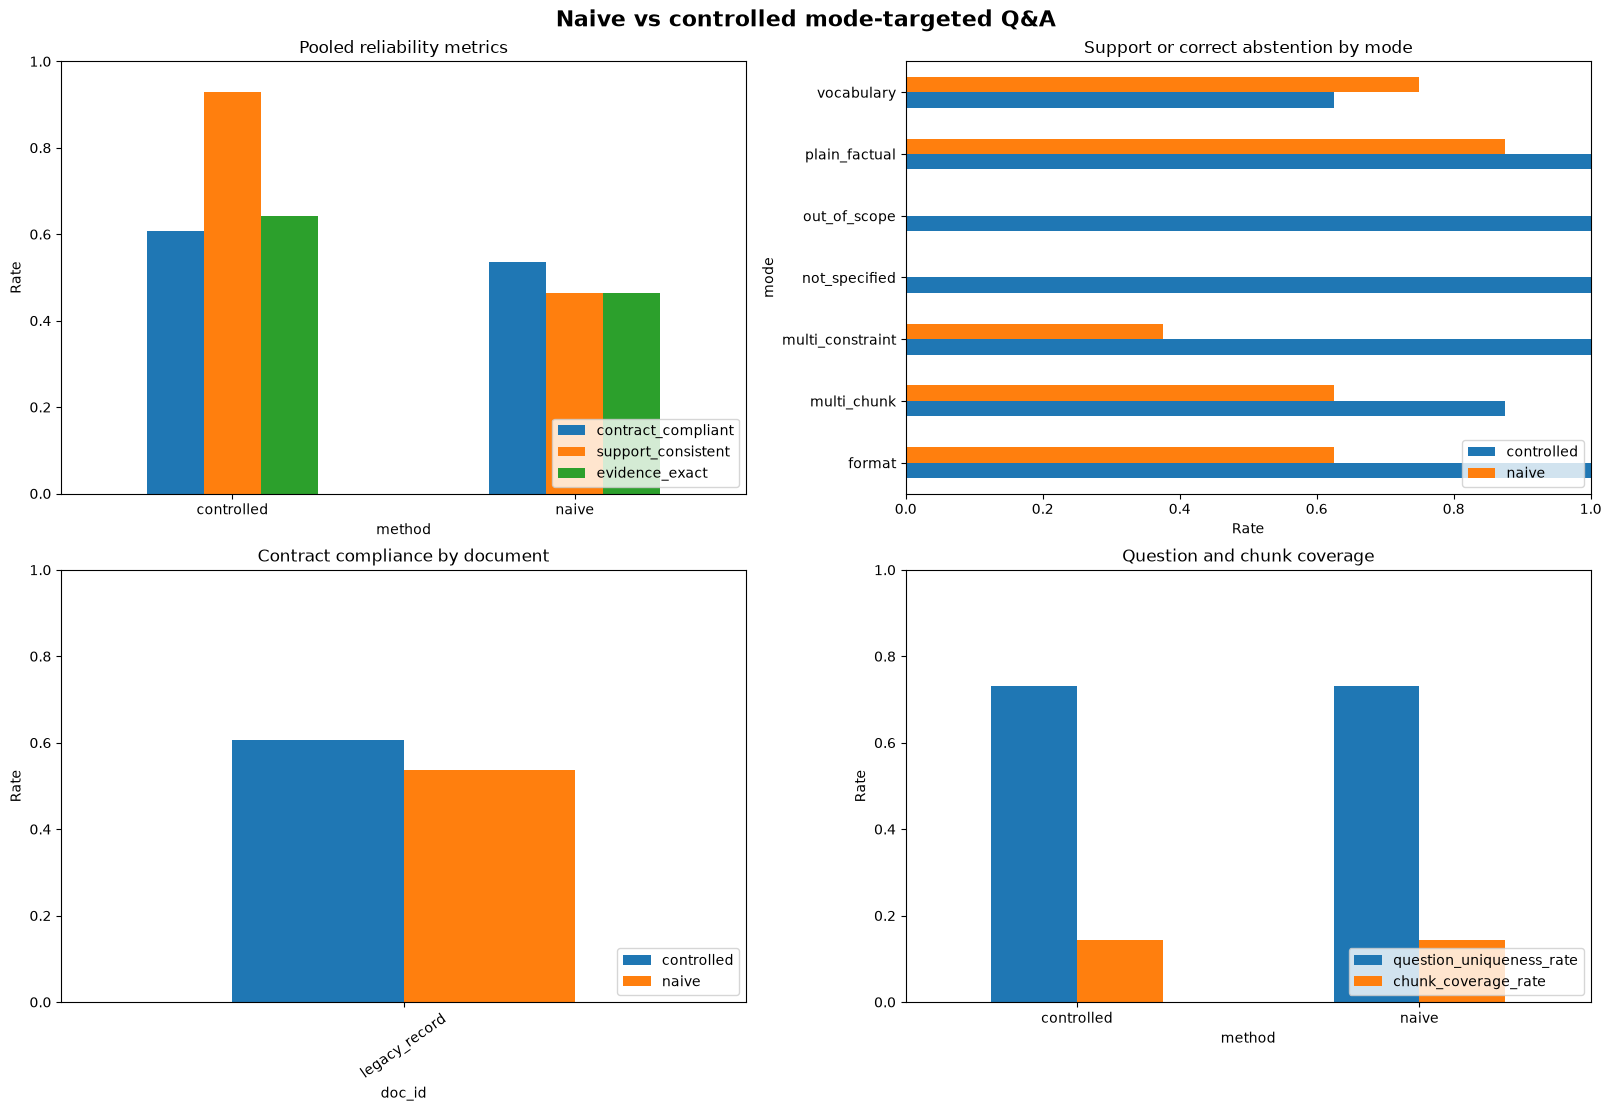

Saved final dashboard to 
/home/coder/cibc1-yujia/CIBC1/implementations/qa_text_generation/output/qa_experiments/naive_vs_controlled_das
hboard.png

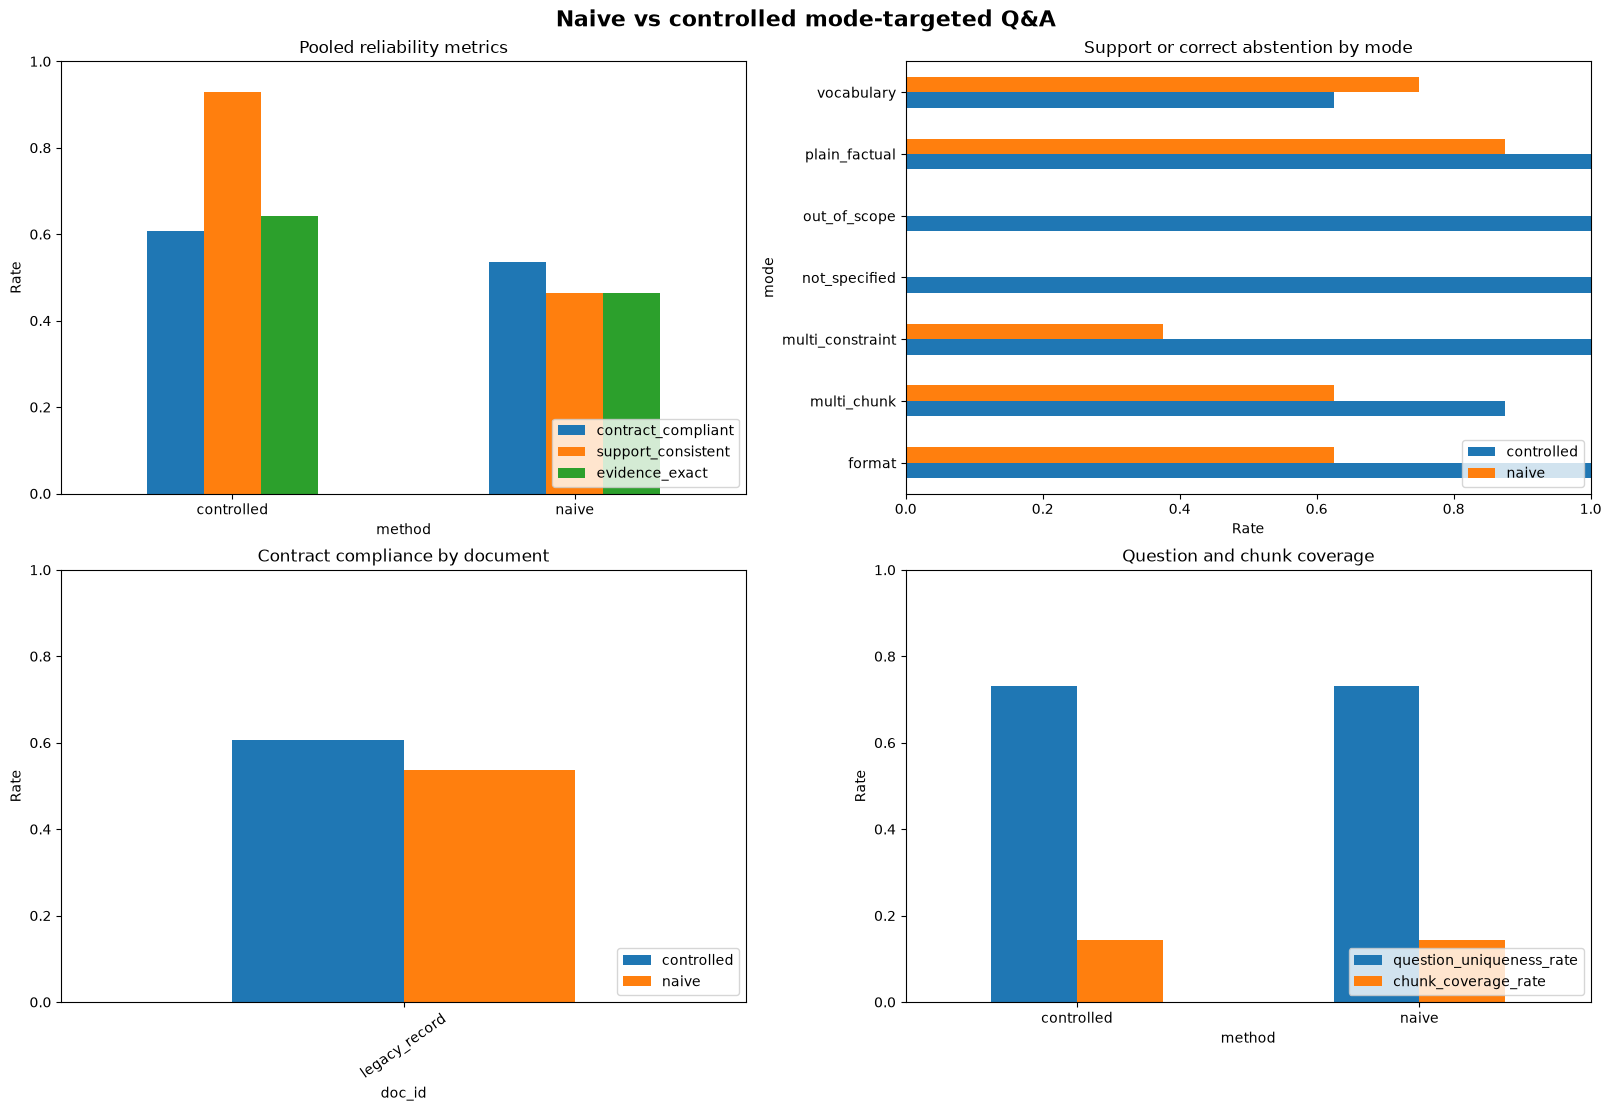

In [30]:
def plot_final_dashboard(metrics, document_summary, diversity_summary, output_path):
    plt.close("all")
    fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)

    pooled = metrics.groupby("method")[["contract_compliant", "support_consistent", "evidence_exact"]].mean()
    pooled.plot.bar(ax=axes[0, 0], ylim=(0, 1), rot=0, title="Pooled reliability metrics")
    axes[0, 0].set_ylabel("Rate")
    axes[0, 0].legend(loc="lower right")

    mode_rates = metrics.groupby(["mode", "method"])["support_consistent"].mean().unstack(fill_value=0)
    mode_rates.plot.barh(ax=axes[0, 1], xlim=(0, 1), title="Support or correct abstention by mode")
    axes[0, 1].set_xlabel("Rate")
    axes[0, 1].legend(loc="lower right")

    doc_rates = document_summary.reset_index().pivot(index="doc_id", columns="method", values="contract_compliance")
    doc_rates.plot.bar(ax=axes[1, 0], ylim=(0, 1), rot=35, title="Contract compliance by document")
    axes[1, 0].set_ylabel("Rate")
    axes[1, 0].legend(loc="lower right")

    coverage = diversity_summary.groupby("method")[["question_uniqueness_rate", "chunk_coverage_rate"]].mean()
    coverage.plot.bar(ax=axes[1, 1], ylim=(0, 1), rot=0, title="Question and chunk coverage")
    axes[1, 1].set_ylabel("Rate")
    axes[1, 1].legend(loc="lower right")

    fig.suptitle("Naive vs controlled mode-targeted Q&A", fontsize=16, fontweight="bold")
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    return fig

DASHBOARD_PATH = OUT_DIR / "naive_vs_controlled_dashboard.png"
fig = plot_final_dashboard(metrics, document_summary, diversity_summary, DASHBOARD_PATH)
display(fig)
console.print(f"Saved final dashboard to {DASHBOARD_PATH}")


## 5. Review examples

Inspect examples from every controlled mode before drawing conclusions. In particular, verify that multi-chunk questions genuinely require both chunks and that out-of-scope/not-specified answers abstain rather than merely returning an empty answer.

In [31]:
display(
    results[["method", "mode", "chunk_id", "paired_chunk_id", "question", "answer", "evidence", "abstention_correct"]]
    .sort_values(["mode", "method"])
    .head(20)
)


,method,mode,chunk_id,paired_chunk_id,question,answer,evidence,abstention_correct
57,controlled,format,12,13,What are the two conditions under which the Cr...,"{'conditions': ['if you should default', 'if y...",[You authorize the Credit Union to apply the b...,False
64,controlled,format,13,16,What are the conditions under which the Credit...,{'conditions': 'You authorize the Credit Union...,[You authorize the Credit Union to apply the b...,False
71,controlled,format,16,21,What are the conditions under which the Credit...,{'conditions': ['You have made a good faith at...,[The Credit Union is subject to claims and def...,False
78,controlled,format,21,26,What are the conditions under which the Credit...,{'conditions': ['you have made a good faith at...,[The Credit Union is subject to claims and def...,False
85,controlled,format,26,30,What are the two main purposes of the VAU serv...,{'main_purposes': ['update relevant card data ...,[update relevant card data (card numbers and e...,False
92,controlled,format,30,31,What are the two main features of the VAU serv...,{'VAU_service_features': ['The service may upd...,[The service may update relevant card data (ca...,False
99,controlled,format,31,35,What are the eligibility criteria and potentia...,{'eligibility_criteria': 'You must be current ...,[You must be current on all of your Delta Comm...,False
106,controlled,format,35,12,What are the conditions under which you may ha...,{'conditions': ['The purchase must have been m...,[If you are dissatisfied with the goods or ser...,False
1,naive,format,12,13,What are the two conditions under which the Cr...,The Credit Union can apply your share account ...,[You authorize the Credit Union to apply the b...,False
8,naive,format,13,16,What are the conditions under which the Credit...,The Credit Union can apply the balance in your...,[You authorize the Credit Union to apply the b...,False
